# 03. Modelos baseline para término e atraso de contratos

Este notebook cria os primeiros modelos de referência usando o dataset exploratório já produzido.

Modelos:

1. **Regressão baseline:** estima quantos dias a conclusão ficou antes ou depois do prazo vigente.
2. **Classificação baseline:** estima se o contrato ultrapassou o prazo vigente.

O objetivo ainda não é obter o melhor modelo. O objetivo é criar uma referência simples, reproduzível e fácil de explicar.

> Use os resultados apenas para exploração. Antes de uso decisório, valide as regras do prazo vigente, conclusão e datas de corte.


## Definição dos alvos

```text
target_dias_desvio = data_conclusao - data_termino_vigente
```

- valor positivo: conclusão após o prazo;
- zero: conclusão na data do prazo;
- valor negativo: conclusão antes do prazo.

```text
target_atrasou = 1 quando target_dias_desvio > 0
```

Para reduzir vazamento temporal, o notebook escolhe, para cada contrato concluído, o último snapshot **anterior ou igual à data de conclusão**. Datas de conclusão, status final e prazo vigente não entram como características dos modelos.


In [7]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")


## 1. Carregamento do dataset

In [8]:
def find_project_root() -> Path:
    current = Path.cwd().resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "data" / "processed").exists():
            return candidate
    return current.parent if current.name == "notebooks" else current


PROJECT_ROOT = find_project_root()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
METRICS_DIR = PROJECT_ROOT / "artifacts" / "metrics"
PREDICTIONS_DIR = PROJECT_ROOT / "artifacts" / "predictions"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

for directory in [METRICS_DIR, PREDICTIONS_DIR, FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

parquet_path = PROCESSED_DIR / "dataset_exploratorio_contratos.parquet"
#csv_path = PROCESSED_DIR / "dataset_exploratorio_contratos.csv"
csv_path = PROCESSED_DIR / "dataset_modelagem_obras_snapshots.csv"


if parquet_path.exists():
    df = pd.read_parquet(parquet_path)
elif csv_path.exists():
    df = pd.read_csv(csv_path, low_memory=False)
else:
    raise FileNotFoundError(
        "Dataset não encontrado. Execute primeiro o notebook "
        "01_dataset_exploratorio_novas_fontes.ipynb."
    )

for column in ["data_corte", "Data_conclusao", "data_termino_vigente", "Data_OS"]:
    if column in df.columns:
        df[column] = pd.to_datetime(df[column], errors="coerce")

print("Snapshots:", len(df))
print("Contratos:", df["id_contrato"].nunique())


Snapshots: 1435
Contratos: 78


## 2. Preparação da amostra de modelagem

In [9]:
required_columns = [
    #"id_contrato", "data_corte", "Data_conclusao", "data_termino_vigente"
]
missing_columns = [column for column in required_columns if column not in df.columns]
if missing_columns:
    raise ValueError(f"Colunas obrigatórias ausentes: {missing_columns}")

# Mantém somente snapshots com conclusão e prazo vigente conhecidos.
eligible = df.dropna(subset=[
    #"id_contrato", "data_corte", "Data_conclusao", "data_termino_vigente"
]).copy()

# Exclui snapshots posteriores à conclusão.
eligible = eligible[eligible["data_corte"] <= eligible["Data_conclusao"]].copy()

# Um registro por contrato: último snapshot conhecido até a conclusão.
model_data = (
    eligible.sort_values(["id_contrato", "data_corte"])
    .groupby("id_contrato", as_index=False)
    .tail(1)
    .copy()
)

model_data["target_dias_desvio"] = (
    model_data["Data_conclusao"] - model_data["data_termino_vigente"]
).dt.days
model_data["target_atrasou"] = model_data["target_dias_desvio"].gt(0).astype("int8")

print("Contratos elegíveis:", len(model_data))
print("Contratos atrasados:", int(model_data["target_atrasou"].sum()))
print("Contratos sem atraso:", int(model_data["target_atrasou"].eq(0).sum()))
model_data[[
    "id_contrato", "data_corte", "Data_conclusao", "data_termino_vigente",
    "target_dias_desvio", "target_atrasou"
]].head()


KeyError: 'Data_conclusao'

### Verificação mínima

Com poucos contratos, as métricas variam muito. O notebook interrompe a execução se não houver observações ou as duas classes necessárias para a classificação.


In [ ]:
if len(model_data) < 10:
    raise ValueError(
        "Há menos de 10 contratos elegíveis. Valide a cobertura de conclusão e prazo vigente."
    )

if model_data["target_atrasou"].nunique() < 2:
    raise ValueError(
        "A classificação exige contratos atrasados e não atrasados."
    )


## 3. Seleção simples das características

In [ ]:
# Características disponíveis antes da conclusão.
# Colunas finais, identificadores e datas usadas no target não são incluídas.
candidate_numeric = [
    "valor_total_contrato",
    "prazo_total_informado",
    "qtd_parcelas_acumulado",
    "qtd_parcelas_liberadas_acumulado",
    "valor_liberado_acumulado",
    "percentual_financeiro_liberado",
    "atraso_medio_parcela",
    "atraso_maximo_parcela",
    "qtd_aditivos_prazo_acumulado",
    "dias_aditados_acumulado",
    "qtd_aditivos_valor_acumulado",
    "dias_desde_os",
]

candidate_categorical = [
    "tipo_obra",
    "Tipo_de_contrato",
    "nome_fornecedor",
    "Contrato_Paralisado",
]

numeric_features = [c for c in candidate_numeric if c in model_data.columns]
categorical_features = [c for c in candidate_categorical if c in model_data.columns]
features = numeric_features + categorical_features

if not features:
    raise ValueError("Nenhuma característica candidata foi encontrada no dataset.")

print("Características numéricas:", numeric_features)
print("Características categóricas:", categorical_features)


Características numéricas: ['valor_total_contrato', 'prazo_total_informado', 'qtd_parcelas_acumulado', 'qtd_parcelas_liberadas_acumulado', 'valor_liberado_acumulado', 'percentual_financeiro_liberado', 'atraso_medio_parcela', 'atraso_maximo_parcela', 'qtd_aditivos_prazo_acumulado', 'dias_aditados_acumulado', 'qtd_aditivos_valor_acumulado', 'dias_desde_os']
Características categóricas: ['tipo_obra', 'Tipo_de_contrato', 'nome_fornecedor', 'Contrato_Paralisado']


## 4. Divisão temporal entre treino e teste

A divisão é feita pela `data_corte`, sem embaralhar. Os registros mais antigos formam o treino e os mais recentes formam o teste. Isso é mais próximo do uso real do que uma divisão aleatória.


In [ ]:
model_data = model_data.sort_values("data_corte").reset_index(drop=True)
cut_index = int(len(model_data) * 0.80)

train = model_data.iloc[:cut_index].copy()
test = model_data.iloc[cut_index:].copy()

X_train = train[features]
X_test = test[features]
y_reg_train = train["target_dias_desvio"]
y_reg_test = test["target_dias_desvio"]
y_clf_train = train["target_atrasou"]
y_clf_test = test["target_atrasou"]

print("Treino:", len(train), "contratos")
print("Teste:", len(test), "contratos")
print("Última data do treino:", train["data_corte"].max())
print("Primeira data do teste:", test["data_corte"].min())
print("Classes no treino:", y_clf_train.value_counts().to_dict())
print("Classes no teste:", y_clf_test.value_counts().to_dict())


Treino: 34 contratos
Teste: 9 contratos
Última data do treino: 2024-12-17 00:00:00
Primeira data do teste: 2025-03-18 00:00:00
Classes no treino: {1: 26, 0: 8}
Classes no teste: {1: 8, 0: 1}


## 5. Preprocessamento reutilizável

- valores numéricos ausentes recebem a mediana do treino;
- variáveis categóricas ausentes recebem o valor mais frequente;
- categorias são convertidas com one-hot encoding;
- o ajuste ocorre somente no treino por meio do `Pipeline`.


In [ ]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessing = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])


# Parte A. Regressão baseline

O primeiro baseline sempre prevê a **mediana dos dias de desvio observados no treino**. O segundo modelo é uma regressão linear simples, adicionada apenas para verificar se as características fornecem algum ganho sobre a regra ingênua.


In [ ]:
regression_models = {
    "dummy_mediana": Pipeline(steps=[
        ("preprocessing", preprocessing),
        ("model", DummyRegressor(strategy="median")),
    ]),
    "regressao_linear": Pipeline(steps=[
        ("preprocessing", preprocessing),
        ("model", LinearRegression()),
    ]),
}

regression_results = []
regression_predictions = test[["id_contrato", "data_corte", "target_dias_desvio"]].copy()

for name, model in regression_models.items():
    model.fit(X_train, y_reg_train)
    prediction = model.predict(X_test)
    regression_predictions[f"pred_{name}"] = prediction

    regression_results.append({
        "modelo": name,
        "MAE": mean_absolute_error(y_reg_test, prediction),
        "RMSE": mean_squared_error(y_reg_test, prediction) ** 0.5,
        "erro_medio_assinado": float(np.mean(prediction - y_reg_test)),
        "pct_erro_ate_30_dias": float(np.mean(np.abs(prediction - y_reg_test) <= 30) * 100),
    })

regression_metrics = pd.DataFrame(regression_results).sort_values("MAE")
regression_metrics


,modelo,MAE,RMSE,erro_medio_assinado,pct_erro_ate_30_dias
0,dummy_mediana,85.444,109.048,-63.889,33.333
1,regressao_linear,456.551,682.936,-76.131,0.000


In [ ]:
regression_predictions.head(20)


,id_contrato,data_corte,target_dias_desvio,pred_dummy_mediana,pred_regressao_linear
34,205,2025-03-18,238,91.000,775.683
35,290,2025-03-20,113,91.000,190.343
36,173,2025-05-15,167,91.000,711.691
37,283,2025-08-18,85,91.000,252.008
38,201,2025-10-07,113,91.000,196.246
39,158,2025-12-01,313,91.000,"-1,503.442"
40,254,2025-12-15,0,91.000,301.920
41,317,2026-02-09,136,91.000,-231.266
42,377,2026-02-26,229,91.000,15.639


### Interpretação das métricas de regressão

- **MAE:** erro absoluto médio em dias. Quanto menor, melhor.
- **RMSE:** penaliza mais os erros muito grandes. Quanto menor, melhor.
- **Erro médio assinado:** mostra tendência de superestimar ou subestimar.
- **Erro até 30 dias:** percentual de previsões próximas do valor real.


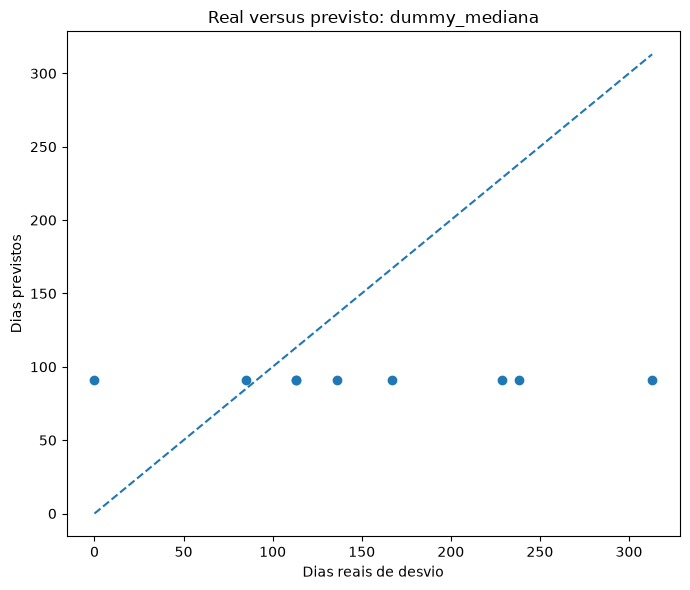

In [ ]:
best_regression_name = regression_metrics.iloc[0]["modelo"]
best_regression_prediction = regression_predictions[f"pred_{best_regression_name}"]

plt.figure(figsize=(7, 6))
plt.scatter(y_reg_test, best_regression_prediction)
limits = [
    min(y_reg_test.min(), best_regression_prediction.min()),
    max(y_reg_test.max(), best_regression_prediction.max()),
]
plt.plot(limits, limits, linestyle="--")
plt.xlabel("Dias reais de desvio")
plt.ylabel("Dias previstos")
plt.title(f"Real versus previsto: {best_regression_name}")
plt.tight_layout()
plt.show()


# Parte B. Classificação baseline

O primeiro baseline sempre prevê a classe mais frequente. O segundo é uma regressão logística simples, que permite avaliar se as características ajudam a separar contratos atrasados e não atrasados.


In [ ]:
classification_models = {
    "dummy_classe_frequente": Pipeline(steps=[
        ("preprocessing", preprocessing),
        ("model", DummyClassifier(strategy="prior")),
    ]),
    "regressao_logistica": Pipeline(steps=[
        ("preprocessing", preprocessing),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
    ]),
}

classification_results = []
classification_predictions = test[["id_contrato", "data_corte", "target_atrasou"]].copy()

for name, model in classification_models.items():
    model.fit(X_train, y_clf_train)
    prediction = model.predict(X_test)
    probability = model.predict_proba(X_test)[:, 1]

    classification_predictions[f"pred_{name}"] = prediction
    classification_predictions[f"prob_{name}"] = probability

    result = {
        "modelo": name,
        "accuracy": accuracy_score(y_clf_test, prediction),
        "balanced_accuracy": balanced_accuracy_score(y_clf_test, prediction),
        "precision": precision_score(y_clf_test, prediction, zero_division=0),
        "recall": recall_score(y_clf_test, prediction, zero_division=0),
        "f1": f1_score(y_clf_test, prediction, zero_division=0),
    }

    # ROC-AUC só existe quando o teste contém as duas classes.
    result["roc_auc"] = (
        roc_auc_score(y_clf_test, probability)
        if y_clf_test.nunique() == 2
        else np.nan
    )
    classification_results.append(result)

classification_metrics = pd.DataFrame(classification_results).sort_values("balanced_accuracy", ascending=False)
classification_metrics


,modelo,accuracy,balanced_accuracy,precision,recall,f1,roc_auc
0,dummy_classe_frequente,0.889,0.500,0.889,1.000,0.941,0.500
1,regressao_logistica,0.889,0.500,0.889,1.000,0.941,0.500


In [ ]:
classification_predictions.head(20)


,id_contrato,data_corte,target_atrasou,pred_dummy_classe_frequente,prob_dummy_classe_frequente,pred_regressao_logistica,prob_regressao_logistica
34,205,2025-03-18,1,1,0.765,1,0.989
35,290,2025-03-20,1,1,0.765,1,0.805
36,173,2025-05-15,1,1,0.765,1,0.999
37,283,2025-08-18,1,1,0.765,1,0.890
38,201,2025-10-07,1,1,0.765,1,0.993
39,158,2025-12-01,1,1,0.765,1,0.992
40,254,2025-12-15,0,1,0.765,1,0.978
41,317,2026-02-09,1,1,0.765,1,0.941
42,377,2026-02-26,1,1,0.765,1,0.881


### Interpretação das métricas de classificação

- **Accuracy:** percentual total de acertos, mas pode enganar quando uma classe domina.
- **Balanced accuracy:** média do desempenho nas duas classes.
- **Precision:** entre os contratos previstos como atrasados, quantos realmente atrasaram.
- **Recall:** entre os contratos que realmente atrasaram, quantos foram identificados.
- **F1:** equilíbrio entre precision e recall.
- **ROC-AUC:** capacidade de ordenar contratos por risco, quando o teste contém as duas classes.


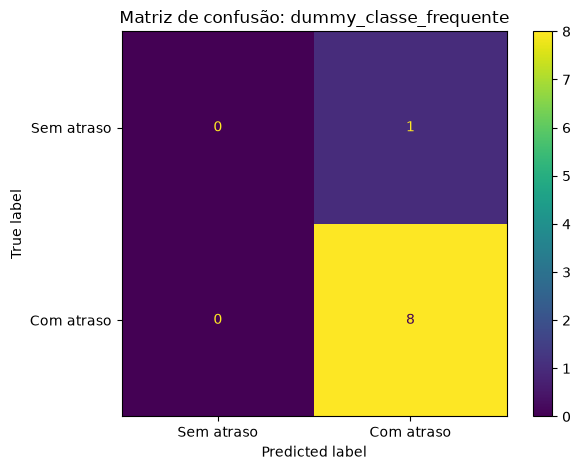

              precision    recall  f1-score   support

  Sem atraso       0.00      0.00      0.00         1
  Com atraso       0.89      1.00      0.94         8

    accuracy                           0.89         9
   macro avg       0.44      0.50      0.47         9
weighted avg       0.79      0.89      0.84         9



In [ ]:
best_classification_name = classification_metrics.iloc[0]["modelo"]
best_classification_model = classification_models[best_classification_name]
best_classification_prediction = classification_predictions[f"pred_{best_classification_name}"]

ConfusionMatrixDisplay.from_predictions(
    y_clf_test,
    best_classification_prediction,
    display_labels=["Sem atraso", "Com atraso"],
    values_format="d",
)
plt.title(f"Matriz de confusão: {best_classification_name}")
plt.tight_layout()
plt.show()

print(classification_report(
    y_clf_test,
    best_classification_prediction,
    target_names=["Sem atraso", "Com atraso"],
    zero_division=0,
))


## 6. Explicação simples da regressão logística

In [ ]:
logistic_pipeline = classification_models["regressao_logistica"]

# Recupera os nomes criados pelo preprocessamento.
feature_names = logistic_pipeline.named_steps["preprocessing"].get_feature_names_out()
coefficients = logistic_pipeline.named_steps["model"].coef_[0]

coefficient_table = (
    pd.DataFrame({
        "caracteristica": feature_names,
        "coeficiente": coefficients,
        "efeito_absoluto": np.abs(coefficients),
    })
    .sort_values("efeito_absoluto", ascending=False)
)

coefficient_table.head(20)


,caracteristica,coeficiente,efeito_absoluto
5,numeric__percentual_financeiro_liberado,1.023,1.023
34,categorical__nome_fornecedor_LUPA CONSTRUCOES ...,-0.771,0.771
35,categorical__nome_fornecedor_MDS SOLUCOES E CO...,0.574,0.574
21,categorical__nome_fornecedor_Bortolon Arquitet...,-0.561,0.561
30,categorical__nome_fornecedor_GIACOMET TERMO ME...,-0.510,0.510
14,categorical__tipo_obra_Reforma Parcial,-0.498,0.498
6,numeric__atraso_medio_parcela,0.479,0.479
7,numeric__atraso_maximo_parcela,0.475,0.475
37,categorical__nome_fornecedor_SCHAFFER & PIAZZA...,-0.437,0.437
10,numeric__qtd_aditivos_valor_acumulado,0.435,0.435


Como ler os coeficientes:

- coeficiente positivo: associado a maior probabilidade de atraso;
- coeficiente negativo: associado a menor probabilidade de atraso;
- magnitude maior: maior influência dentro deste modelo linear;
- associação não significa causalidade.


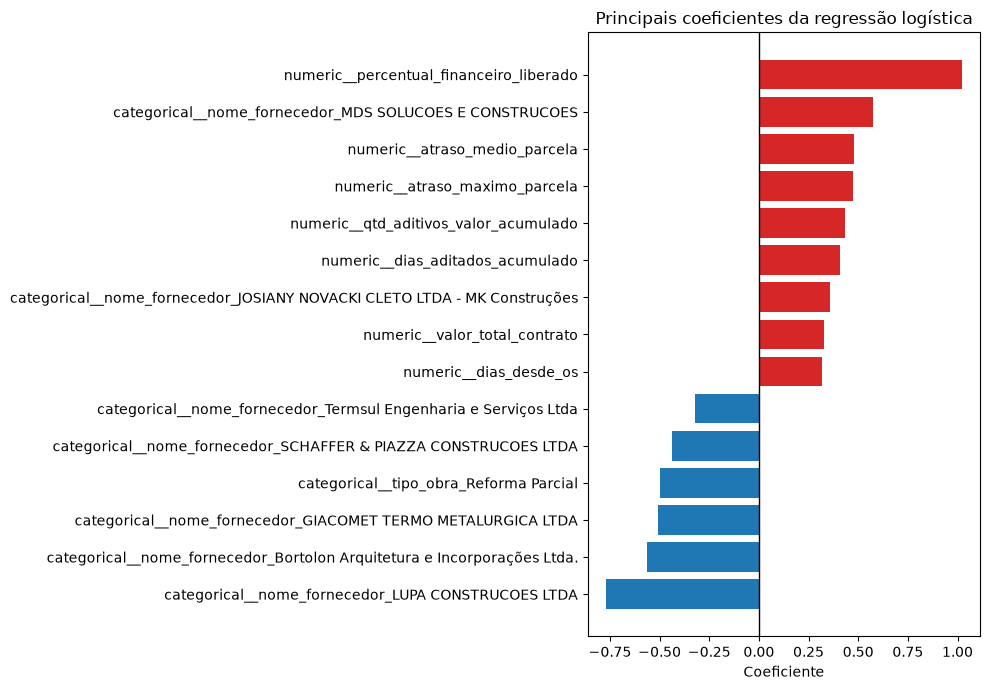

In [ ]:
top_coefficients = coefficient_table.head(15).sort_values("coeficiente")

plt.figure(figsize=(10, 7))
colors = ["tab:red" if value > 0 else "tab:blue" for value in top_coefficients["coeficiente"]]
plt.barh(top_coefficients["caracteristica"], top_coefficients["coeficiente"], color=colors)
plt.axvline(0, color="black", linewidth=1)
plt.title("Principais coeficientes da regressão logística")
plt.xlabel("Coeficiente")
plt.tight_layout()
plt.show()


## 7. Salvamento das métricas e previsões

In [ ]:
regression_metrics.to_csv(
    METRICS_DIR / "baseline_regressao_metricas.csv",
    index=False,
    encoding="utf-8-sig",
)
classification_metrics.to_csv(
    METRICS_DIR / "baseline_classificacao_metricas.csv",
    index=False,
    encoding="utf-8-sig",
)
regression_predictions.to_csv(
    PREDICTIONS_DIR / "baseline_regressao_previsoes.csv",
    index=False,
    encoding="utf-8-sig",
)
classification_predictions.to_csv(
    PREDICTIONS_DIR / "baseline_classificacao_previsoes.csv",
    index=False,
    encoding="utf-8-sig",
)
coefficient_table.to_csv(
    METRICS_DIR / "regressao_logistica_coeficientes.csv",
    index=False,
    encoding="utf-8-sig",
)

print("Resultados salvos em:")
print(METRICS_DIR)
print(PREDICTIONS_DIR)


Resultados salvos em:
C:\Users\Gabriel\OneDrive\Documentos\projeto_previsao_termino_obras\artifacts\metrics
C:\Users\Gabriel\OneDrive\Documentos\projeto_previsao_termino_obras\artifacts\predictions
